In [1]:
import torch
import numpy as np

import sys
sys.path.append("../")

from utils.set_seed import set_seed
from data.utils.r_peak_processing import detect_r_peaks
from models.lightx3ecg import LightX3ECG, LightSEModule, LightSEResBlock, LightSEResNet18, DSConv1d
from interpretability_methods.ig import run_ig
from interpretability_methods.lime import run_lime
import pandas as pd

c:\Users\oladipea\Documents\EKG-HAN\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
set_seed(10)
device = torch.device('cuda') if torch.cuda.is_available() else torch.device("cpu")

In [3]:
lightx3ecg = torch.load("model_pths/lightx3ecg.pth", map_location=device, weights_only=False)

lightx3ecg_model = LightX3ECG()
lightx3ecg_model.load_state_dict(lightx3ecg)
# dummy = torch.zeros(1, 5000, 12)
lightx3ecg_model.to(device)
lightx3ecg_model.eval()

LightX3ECG(
  (backbone_0): LightSEResNet18(
    (stem): Sequential(
      (0): Conv1d(1, 64, kernel_size=(15,), stride=(2,), padding=(7,))
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool1d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    )
    (stage_0): Sequential(
      (0): LightSEResBlock(
        (conv_1): DSConv1d(
          (dw_conv): Conv1d(64, 64, kernel_size=(7,), stride=(1,), padding=(3,), groups=64, bias=False)
          (pw_conv): Conv1d(64, 64, kernel_size=(1,), stride=(1,), bias=False)
        )
        (identity): Identity()
        (conv_2): DSConv1d(
          (dw_conv): Conv1d(64, 64, kernel_size=(7,), stride=(1,), padding=(3,), groups=64, bias=False)
          (pw_conv): Conv1d(64, 64, kernel_size=(1,), stride=(1,), bias=False)
        )
        (convs): Sequential(
          (0): DSConv1d(
            (dw_conv): Conv1d(64, 64, kernel_size=(7,), stride=(1,), padding=

In [4]:
samples = np.load(r"samples/A.npy", allow_pickle=True)
metadata = pd.read_csv("metadata.csv")

In [5]:
torch.use_deterministic_algorithms(False)
misclassified_samples = []
properly_classified_samples = []
for idx, sample in enumerate(samples[1:10]):
    sample = torch.tensor(sample['ecg']).unsqueeze(dim=0).to(device)
    predicted = torch.argmax(lightx3ecg_model(sample), dim=1)[0]
    if predicted != 0:
        misclassified_samples.append(idx)
    if predicted == 0:
        properly_classified_samples.append(idx)

print(len(properly_classified_samples), len(misclassified_samples))

8 1


   ECG_ID AHA_Code Patient_ID  Age Sex     N        Date
1  A00002        1     S00002   32   M  6000  2019-09-03
Computing Integrated Gradients attributions...


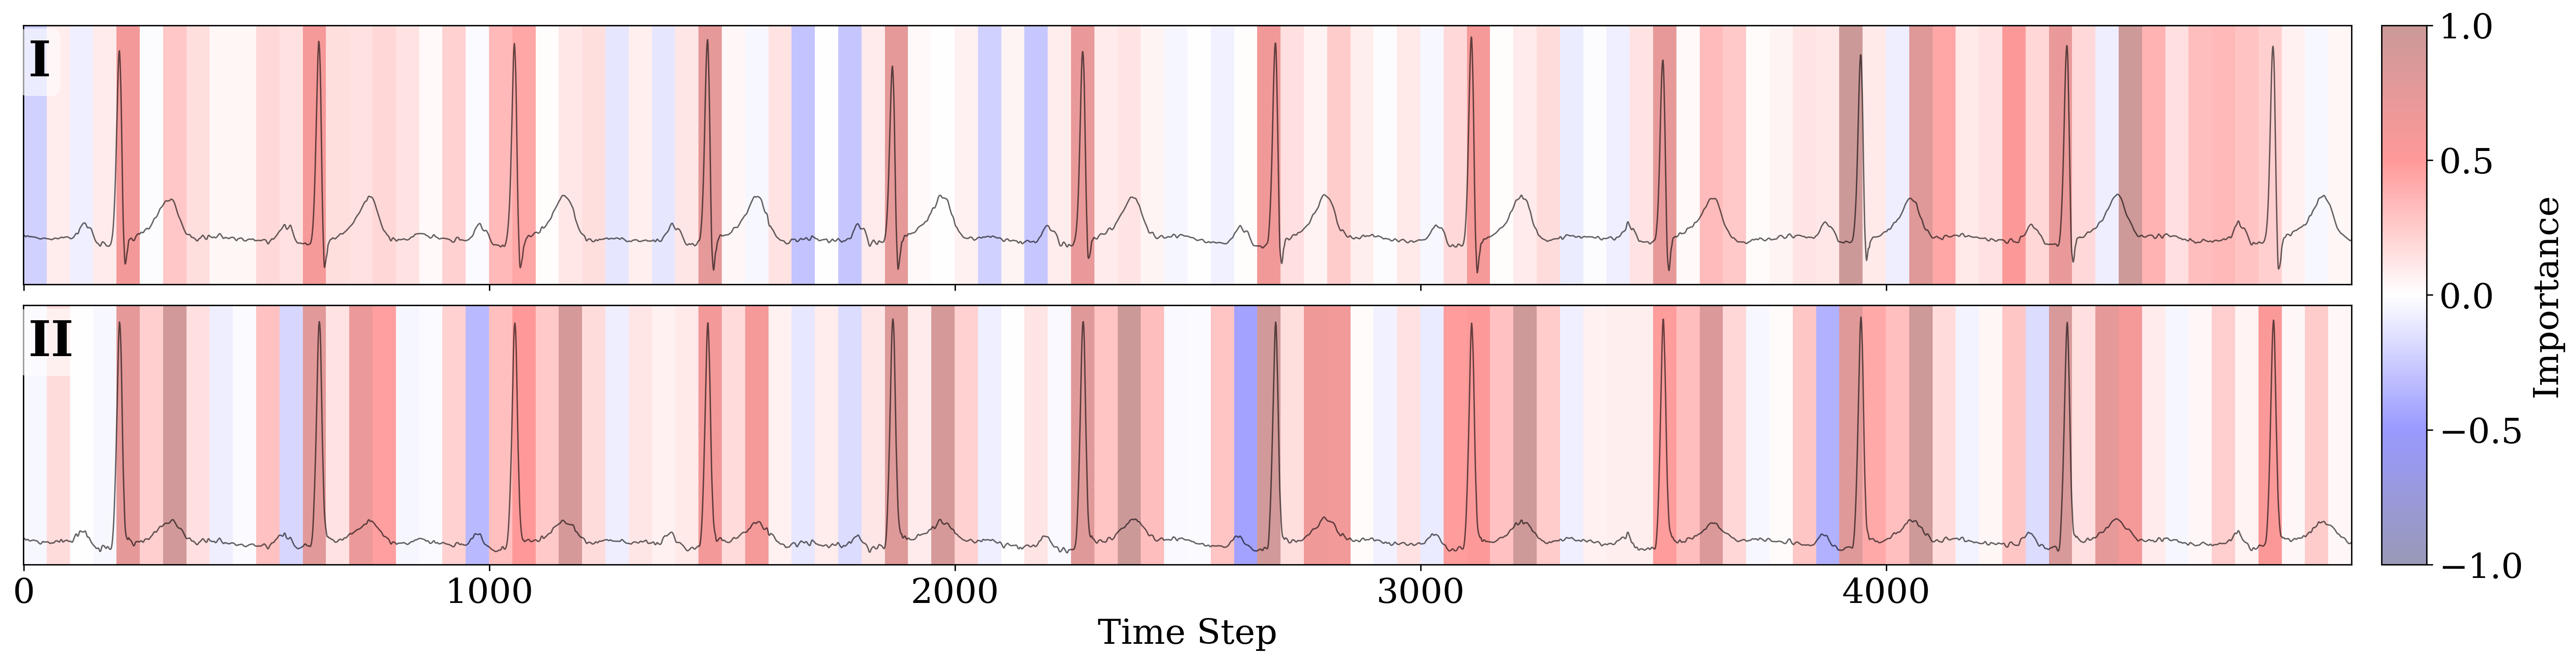

Attribution Range (Lead II): -0.4495 to 1.0000
Mean Abs Attribution (Lead II): 0.3049
Number of windows: 100
Window size: 50 samples
RR mode: n/a
Actual label 0 - . Predicted 0


In [6]:
idx = 0
x = torch.tensor(samples[idx]['ecg'], dtype=torch.float32) 
x = x[:, :5000].unsqueeze(0).to(device)  
print(metadata[metadata['ECG_ID'] == samples[idx]['ecg_id']])

lightx3ecg_ig_attr = run_ig(model=lightx3ecg_model, x=x, y_true_description="", y_true=0, baseline='zero', window_size=50, leads=[0,1])

   ECG_ID AHA_Code Patient_ID  Age Sex     N        Date
1  A00002        1     S00002   32   M  6000  2019-09-03
ECG LIME features: 1200
Computing LIME attributions...


Lime attribution: 100%|██████████| 100/100 [00:31<00:00,  3.18it/s]


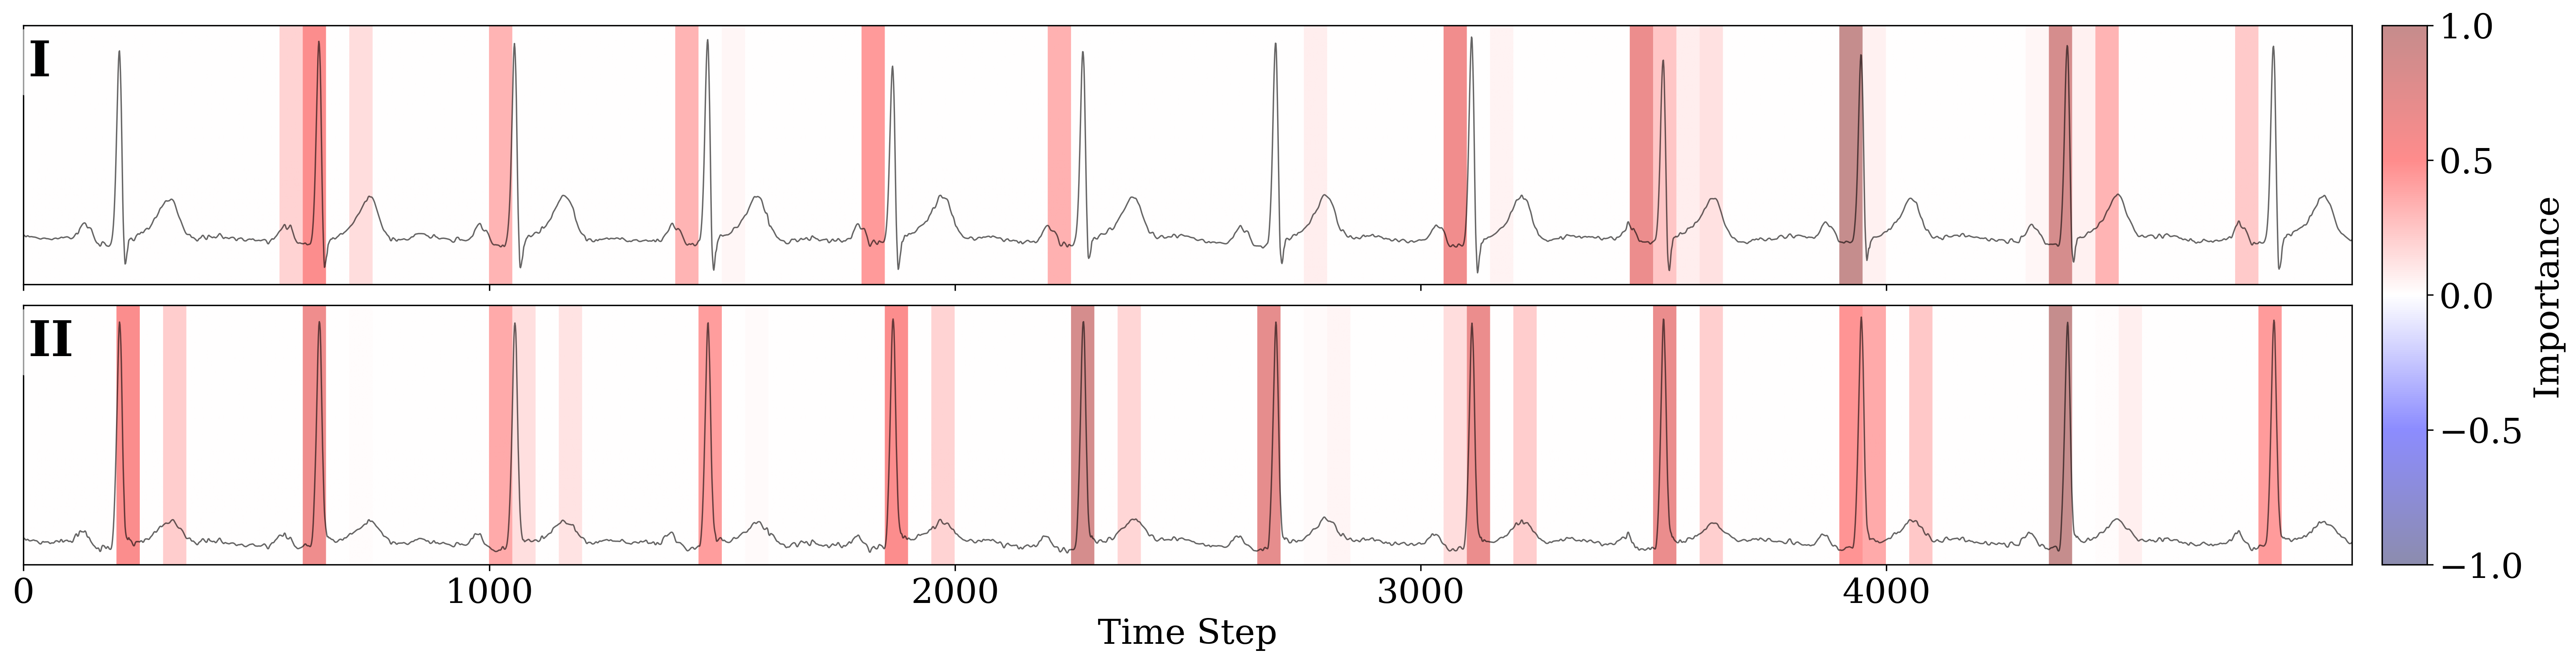

Lead   I | Range [0.000, 1.000] | Mean |attr|: 0.0674
Lead  II | Range [0.000, 1.000] | Mean |attr|: 0.0947

RR mode: n/a
Actual label 0 - . Predicted 0


In [7]:
idx = 0
x = torch.tensor(samples[idx]['ecg'], dtype=torch.float32) 
x = x[:, :5000].unsqueeze(0).to(device)  
print(metadata[metadata['ECG_ID'] == samples[idx]['ecg_id']])

lightx3ecg_lime_attr = run_lime(model=lightx3ecg_model, x=x, y_true_description="", y_true=0, baseline='zero', leads=[0,1])